In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import subprocess

In [2]:
# Obtain the project root directory
project_root = Path.cwd().parent
csv_path = project_root / 'results' / 'timings.csv'

# Read data
df = pd.read_csv(csv_path, dtype={'code_version': str})

# Select the repaired E5 experimental data
e5 = df.loc[
    (df['experiment'] == 'E5_insert_order')
   & (df['code_version'] == '814d553')
    & (df['session_id'] == 'a38baf676d48')
    & (df['member'] == 'fenghao')
    & (df['machine_id'] == 'fenghao-pc')
].copy()

# Check the total number of transactions and the record count for each operation.
print(f'E5 Number of data rows：{len(e5)}')

display(
    e5.groupby(['operation', 'insert_order'])
    .size()
    .unstack()
)


E5 Number of data rows：840


insert_order,nearly_sorted,random,reversed,sorted
operation,,,,
build,105,105,105,105
point_hit,105,105,105,105


In [3]:
# Only select the build operation for E5
e5_build = e5.loc[
    e5['operation'] == 'build'
].copy()

# Convert nanoseconds to milliseconds
e5_build['build_ms'] = e5_build['total_ns'] / 1_000_000

# Statistical analysis is conducted based on data size, index type and insertion order.
e5_build_summary = (
    e5_build.groupby(
        ['n_keys', 'index_type', 'insert_order'],
        as_index=False
    )
    .agg(
        reps=('rep', 'size'),
        mean_ms=('build_ms', 'mean'),
        median_ms=('build_ms', 'median'),
        std_ms=('build_ms', 'std'),
        q1_ms=('build_ms', lambda x: x.quantile(0.25)),
        q3_ms=('build_ms', lambda x: x.quantile(0.75)),
    )
)

# Calculate the interquartile range
e5_build_summary['iqr_ms'] = (
    e5_build_summary['q3_ms']
    - e5_build_summary['q1_ms']
)

# Check the statistical results
assert len(e5_build_summary) == 84
assert e5_build_summary['reps'].eq(5).all()

print(f'Total number of experimental configurations constructed：{len(e5_build_summary)}')

# Examine the results of seven types of indexes and four types of orders under the maximum data size condition
display(
    e5_build_summary.loc[
        e5_build_summary['n_keys'] == 100_000
    ].sort_values(
        ['index_type', 'insert_order']
    ).round(3)
)


Total number of experimental configurations constructed：84


,n_keys,index_type,insert_order,reps,mean_ms,median_ms,std_ms,q1_ms,q3_ms,iqr_ms
56,100000,avl_tree,nearly_sorted,5,556.277,556.545,3.148,555.550,557.639,2.089
57,100000,avl_tree,random,5,508.862,508.028,3.704,507.727,510.218,2.492
58,100000,avl_tree,reversed,5,458.409,458.428,2.561,457.236,459.964,2.728
59,100000,avl_tree,sorted,5,498.589,497.584,2.313,496.931,500.565,3.634
60,100000,bplus_tree,nearly_sorted,5,177.369,177.744,2.294,175.062,179.488,4.426
61,100000,bplus_tree,random,5,192.822,191.211,4.406,190.527,191.680,1.153
62,100000,bplus_tree,reversed,5,170.307,169.835,1.557,169.472,170.162,0.690
63,100000,bplus_tree,sorted,5,164.943,164.689,0.822,164.278,165.766,1.488
64,100000,hash_table,nearly_sorted,5,136.178,138.476,4.563,132.461,139.609,7.148
65,100000,hash_table,random,5,133.232,130.397,6.166,130.019,132.272,2.253


Saved location: /project/analysis/figures_E5/E5_build_by_order.png


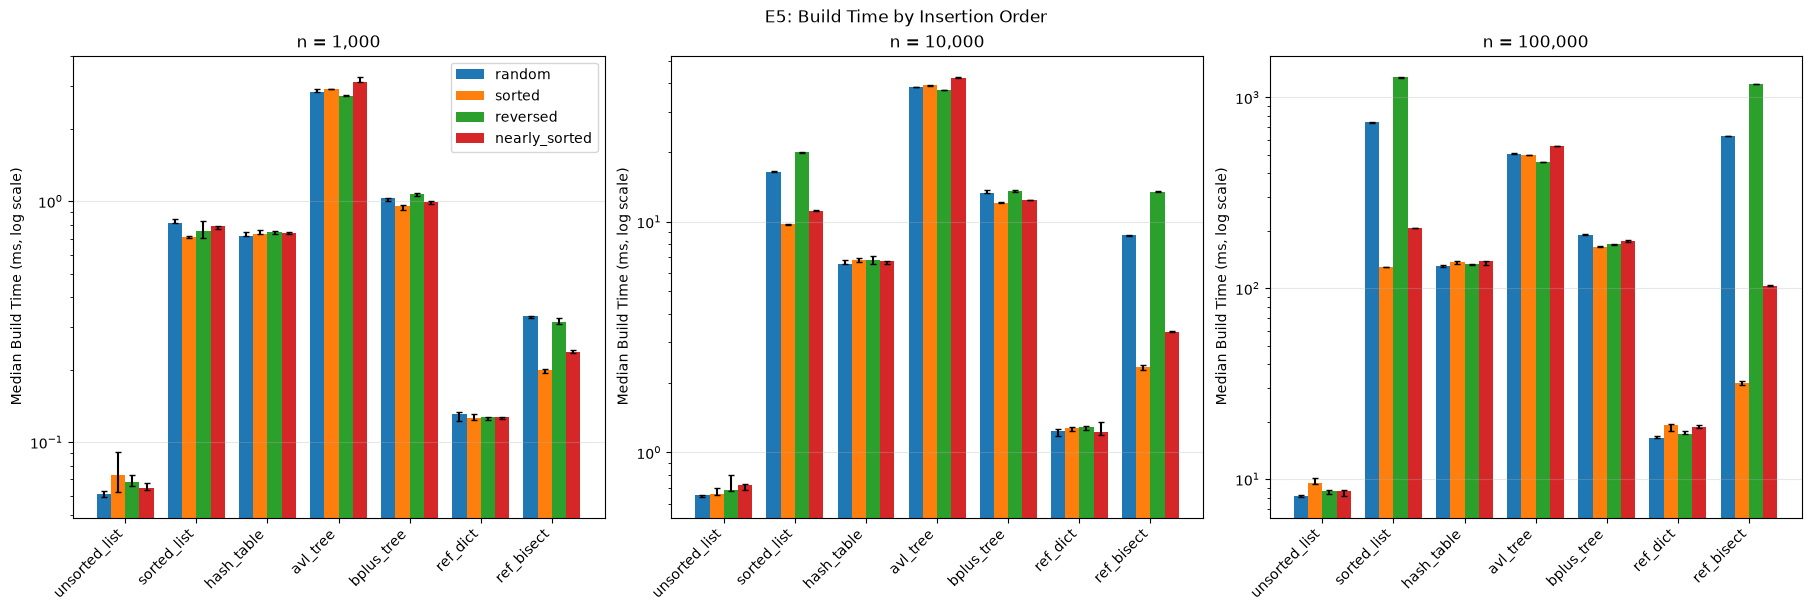

In [4]:
# Create the E5 chart directory
fig_dir = project_root / 'analysis' / 'figures_E5'
fig_dir.mkdir(parents=True, exist_ok=True)

# Set up indexes, insert sequence and data size
indexes = [
    'unsorted_list', 'sorted_list', 'hash_table',
    'avl_tree', 'bplus_tree', 'ref_dict', 'ref_bisect'
]
orders = ['random', 'sorted', 'reversed', 'nearly_sorted']
sizes = [1_000, 10_000, 100_000]

fig, axes = plt.subplots(
    1, 3, figsize=(18, 6), constrained_layout=True
)

x = np.arange(len(indexes))
width = 0.2

# Draw separately for the three different scales
for ax, n in zip(axes, sizes):
    for i, order in enumerate(orders):
        data = (
            e5_build_summary.loc[
                (e5_build_summary['n_keys'] == n)
                & (e5_build_summary['insert_order'] == order)
            ]
            .set_index('index_type')
            .reindex(indexes)
        )

        # Use the median and IQR error bars
        median = data['median_ms'].to_numpy()
        lower = median - data['q1_ms'].to_numpy()
        upper = data['q3_ms'].to_numpy() - median

        ax.bar(
            x + (i - 1.5) * width,
            median,
            width,
            yerr=[lower, upper],
            capsize=2,
            label=order,
        )

    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(indexes, rotation=45, ha='right')
    ax.set_title(f'n = {n:,}')
    ax.set_ylabel('Median Build Time (ms, log scale)')
    ax.grid(axis='y', alpha=0.3)

axes[0].legend()
fig.suptitle('E5: Build Time by Insertion Order')

# Save plt
fig_path = fig_dir / 'E5_build_by_order.png'
fig.savefig(fig_path, dpi=300, bbox_inches='tight')

print(f'Saved location: {fig_path}')
plt.show()


In [5]:
# Search for the record of the hit point for option E5
e5_lookup = e5.loc[
    e5['operation'] == 'point_hit'
].copy()

# Convert the total batch processing time into the number of microseconds for each query on average.
e5_lookup['us_per_query'] = (
    e5_lookup['total_ns'] / e5_lookup['n_ops'] / 1_000
)

# Summarized by scale, index type and insertion order
e5_lookup_summary = (
    e5_lookup.groupby(
        ['n_keys', 'index_type', 'insert_order'],
        as_index=False
    )
    .agg(
        reps=('rep', 'size'),
        mean_us=('us_per_query', 'mean'),
        median_us=('us_per_query', 'median'),
        q1_us=('us_per_query', lambda x: x.quantile(0.25)),
        q3_us=('us_per_query', lambda x: x.quantile(0.75)),
    )
)

# Calculate the interquartile range
e5_lookup_summary['iqr_us'] = (
    e5_lookup_summary['q3_us']
    - e5_lookup_summary['q1_us']
)

# Check for completeness
assert len(e5_lookup_summary) == 84
assert e5_lookup_summary['reps'].eq(5).all()

print(f'Total number of Point Lookup configurations：{len(e5_lookup_summary)}')

# Check the query performance at the maximum scale
display(
    e5_lookup_summary.loc[
        e5_lookup_summary['n_keys'] == 100_000
    ].sort_values(
        ['index_type', 'insert_order']
    ).round(3)
)


Total number of Point Lookup configurations：84


,n_keys,index_type,insert_order,reps,mean_us,median_us,q1_us,q3_us,iqr_us
56,100000,avl_tree,nearly_sorted,5,1.313,1.273,1.240,1.394,0.155
57,100000,avl_tree,random,5,1.283,1.303,1.196,1.339,0.143
58,100000,avl_tree,reversed,5,1.188,1.190,1.163,1.233,0.071
59,100000,avl_tree,sorted,5,1.200,1.221,1.138,1.232,0.095
60,100000,bplus_tree,nearly_sorted,5,1.786,1.659,1.642,1.890,0.248
61,100000,bplus_tree,random,5,1.871,1.789,1.765,2.017,0.252
62,100000,bplus_tree,reversed,5,1.907,1.881,1.832,1.985,0.153
63,100000,bplus_tree,sorted,5,1.809,1.791,1.720,1.826,0.106
64,100000,hash_table,nearly_sorted,5,0.711,0.709,0.678,0.745,0.067
65,100000,hash_table,random,5,0.656,0.636,0.634,0.674,0.040


Saved location: /project/analysis/figures_E5/E5_lookup_by_order.png


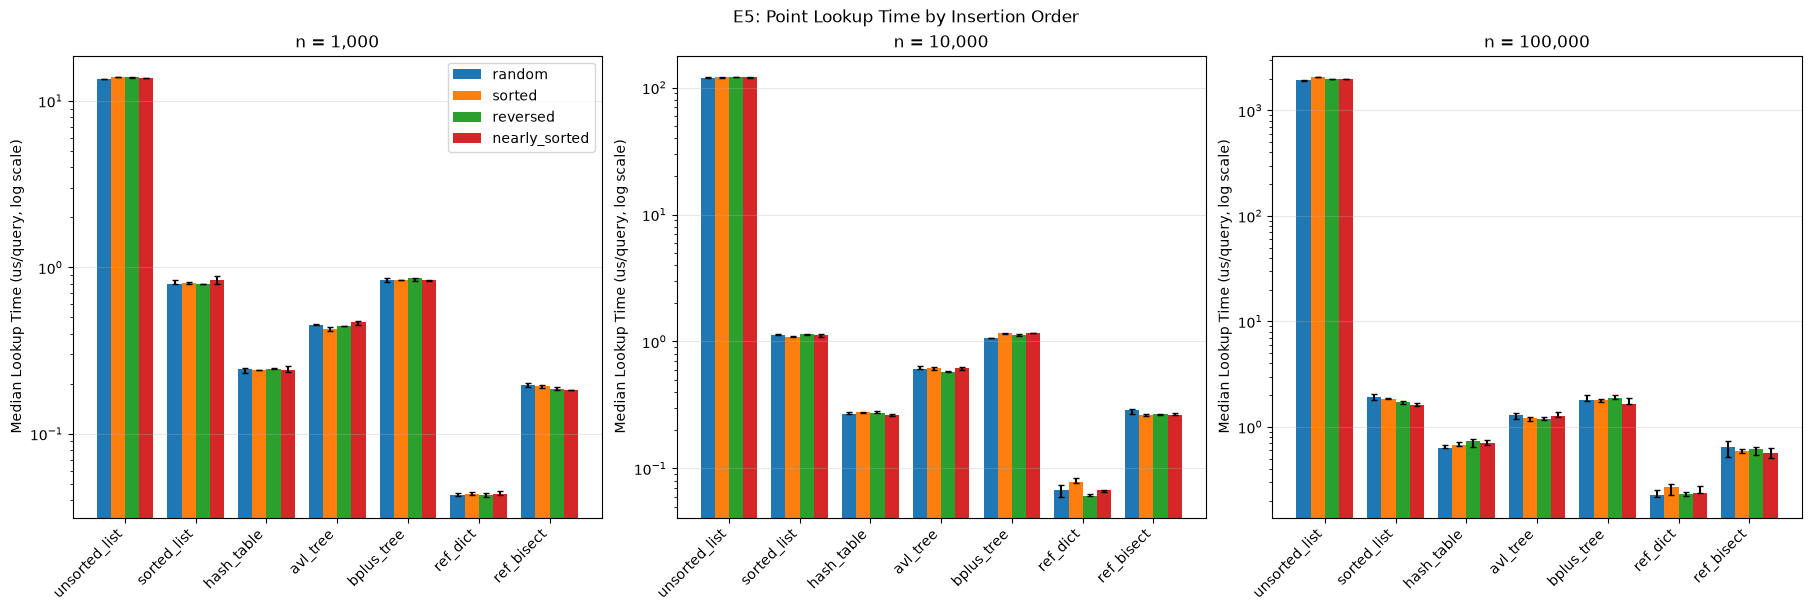

In [6]:
# Draw a comparison chart of the search time for point E5
fig_lookup, axes_lookup = plt.subplots(
    1, 3, figsize=(18, 6), constrained_layout=True
)

x = np.arange(len(indexes))
width = 0.2

# Compare four insertion orders under three different scales
for ax, n in zip(axes_lookup, sizes):
    for i, order in enumerate(orders):
        data = (
            e5_lookup_summary.loc[
                (e5_lookup_summary['n_keys'] == n)
                & (e5_lookup_summary['insert_order'] == order)
            ]
            .set_index('index_type')
            .reindex(indexes)
        )

        # Present the query execution time and fluctuations using the median and IQR
        median = data['median_us'].to_numpy()
        lower = median - data['q1_us'].to_numpy()
        upper = data['q3_us'].to_numpy() - median

        ax.bar(
            x + (i - 1.5) * width,
            median,
            width,
            yerr=[lower, upper],
            capsize=2,
            label=order,
        )

    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(indexes, rotation=45, ha='right')
    ax.set_title(f'n = {n:,}')
    ax.set_ylabel('Median Lookup Time (us/query, log scale)')
    ax.grid(axis='y', alpha=0.3)

axes_lookup[0].legend()
fig_lookup.suptitle('E5: Point Lookup Time by Insertion Order')

# Save plt
lookup_fig_path = fig_dir / 'E5_lookup_by_order.png'
fig_lookup.savefig(
    lookup_fig_path,
    dpi=300,
    bbox_inches='tight'
)

print(f'Saved location: {lookup_fig_path}')
plt.show()


In [7]:
# The counters for the construction operations to be analyzed and the structural indicators
metric_cols = [
    'comparisons',
    'nodes_visited',
    'rotations',
    'splits',
    'resizes',
    'height',
]

# Build records using E5
e5_structure = e5_build.copy()

# Convert the indicators into numerical values and retain the null values that are not applicable.
for col in metric_cols:
    e5_structure[col] = pd.to_numeric(
        e5_structure[col],
        errors='coerce'
    )

# Summarized by data size, index type and insertion order
e5_structure_summary = (
    e5_structure.groupby(
        ['n_keys', 'index_type', 'insert_order'],
        as_index=False
    )[metric_cols]
    .median()
)

# Check the total number of configurations
assert len(e5_structure_summary) == 84

print('Total configurations:', len(e5_structure_summary))

# View the structural information at the maximum scale
display(
    e5_structure_summary.loc[
        e5_structure_summary['n_keys'] == 100_000
    ].round(2)
)


Total configurations: 84


,n_keys,index_type,insert_order,comparisons,nodes_visited,rotations,splits,resizes,height
56,100000,avl_tree,nearly_sorted,1714899.0,1714899.0,118725.0,0.0,0.0,20.0
57,100000,avl_tree,random,1547536.0,1547536.0,69862.0,0.0,0.0,20.0
58,100000,avl_tree,reversed,1568929.0,1568929.0,99983.0,0.0,0.0,17.0
59,100000,avl_tree,sorted,1568929.0,1568929.0,99983.0,0.0,0.0,17.0
60,100000,bplus_tree,nearly_sorted,1599891.0,389875.0,0.0,6137.0,0.0,4.0
61,100000,bplus_tree,random,1542694.0,382532.0,0.0,4834.0,0.0,4.0
62,100000,bplus_tree,reversed,1841281.0,390976.0,0.0,6661.0,0.0,4.0
63,100000,bplus_tree,sorted,1471375.0,390480.0,0.0,6635.0,0.0,4.0
64,100000,hash_table,nearly_sorted,56021.0,100000.0,0.0,0.0,15.0,NaN
65,100000,hash_table,random,55717.0,100000.0,0.0,0.0,15.0,NaN


In [8]:
# Calculate the growth rate of construction time for each of the seven indexes under four different insertion orders
growth_records = []

for (index_type, order), group in e5_build_summary.groupby(
    ['index_type', 'insert_order']
):
    group = group.sort_values('n_keys')

    # Using the median construction time for three different data scales
    x = np.log10(group['n_keys'].to_numpy(dtype=float))
    y = np.log10(group['median_ms'].to_numpy(dtype=float))

    # Fit log(time) = slope * log(n) + intercept
    slope, intercept = np.polyfit(x, y, 1)

    growth_records.append({
        'index_type': index_type,
        'insert_order': order,
        'log_log_slope': slope,
    })

# Summarize the growth rate of 7 types of indexes × 4 types of sequences
e5_growth = pd.DataFrame(growth_records)

assert len(e5_growth) == 28

# Arrange the results into a table for comparison.
growth_table = e5_growth.pivot(
    index='index_type',
    columns='insert_order',
    values='log_log_slope'
)

display(
    growth_table[
        ['random', 'sorted', 'reversed', 'nearly_sorted']
    ].round(3)
)


insert_order,random,sorted,reversed,nearly_sorted
index_type,,,,
avl_tree,1.126,1.115,1.112,1.125
bplus_tree,1.135,1.119,1.100,1.126
hash_table,1.130,1.135,1.126,1.138
ref_bisect,1.636,1.102,1.784,1.319
ref_dict,1.051,1.093,1.067,1.084
sorted_list,1.480,1.130,1.615,1.209
unsorted_list,1.066,1.059,1.052,1.064
